In [1]:
dataset_path = "/home/ekontogi/Diploma-Thesis/hdfs_anomaly_detection/data/tokenized_dataset"

In [2]:
from datasets import load_from_disk

ds = load_from_disk(dataset_path)
train_ds = ds['train']

/home/ekontogi/.virtualenvs/hdfs_anomaly_detection/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from flwr_datasets.partitioner import PathologicalPartitioner

pathological_partitioner = PathologicalPartitioner(
    num_partitions=2, partition_by="label", num_classes_per_partition=1
)

In [5]:
pathological_partitioner.dataset = train_ds

In [6]:
p0 = pathological_partitioner.load_partition(partition_id=0)

In [7]:
p0

Dataset({
    features: ['label', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 11402
})

In [8]:
p1 = pathological_partitioner.load_partition(partition_id=1)

In [9]:
p1

Dataset({
    features: ['label', '__index_level_0__', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3296
})

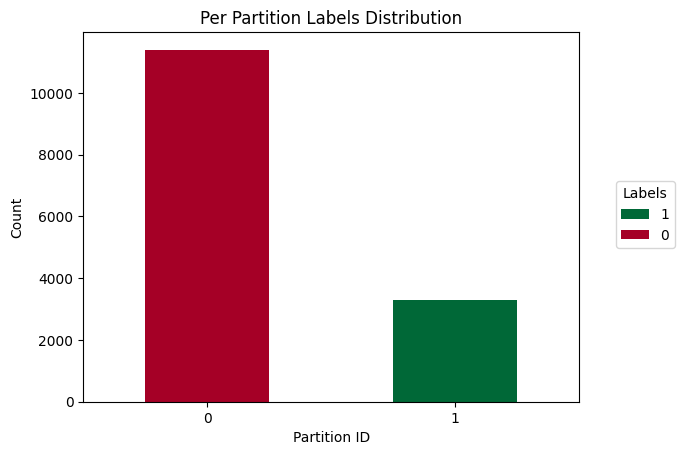

In [10]:
from flwr_datasets.visualization import plot_label_distributions

fig, ax, df = plot_label_distributions(
    pathological_partitioner,
    label_name="label",
    plot_type="bar",
    size_unit="absolute",
    partition_id_axis="x",
    legend=True,
    verbose_labels=True,
    title="Per Partition Labels Distribution",
)
